# Experiment 2 V2 — Exploratory analysis of the noisy matched dataset

This notebook reads **only saved observations and patient metadata**. It does not import the generator, experiment runner, or TemporalTree; it does not fit or apply a predictive model. All descriptive results are computed below. Figures are embedded, not exported to existing result directories.

Run all cells from the repository root (also supported from `experiments/`). Event values describe occurrence, not severity. **R is a deterministic temporal label; FA is a probabilistically sampled outcome.** Repeated histories within matched blocks mean patients are not independent replicates for statistical inference.

## 1. Dataset overview

,Value
Patients,5000.0000
Observation rows (including birth),128645.0000
Event rows,123645.0000
Unique event features,8.0000
Unique row feature names (including birth),9.0000
Documented children,4000.0000
Undocumented children,1000.0000
R prevalence,0.4000
FA prevalence,0.3966


,patients,blocks,documented,R_prevalence,FA_prevalence
partition,,,,,
test,1000,100,800,0.4,0.407
train,4000,400,3200,0.4,0.394


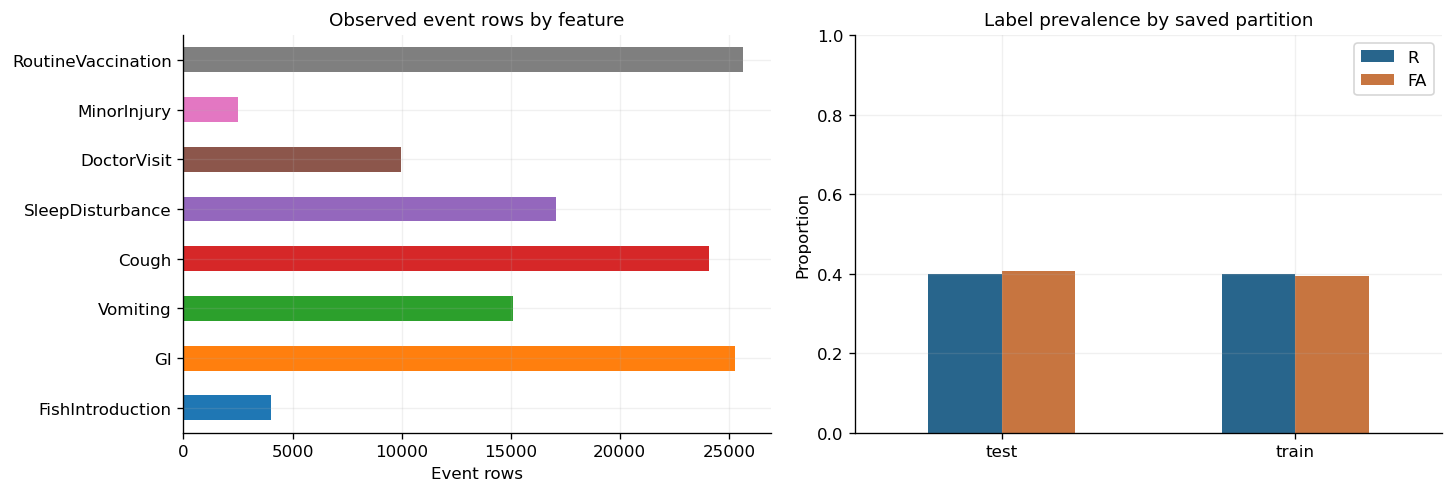

**Interpretation.** Birth-anchor rows are reported separately from the eight event types. Train/test assignments are read from metadata, not resampled.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / 'data/fish_intro_noisy_matched_v2').is_dir():
    ROOT = ROOT.parent
DATA = ROOT / 'data/fish_intro_noisy_matched_v2'
assert DATA.is_dir(), 'Start Jupyter from the repository root or experiments/'
FEATURES = ['FishIntroduction', 'GI', 'Vomiting', 'Cough', 'SleepDisturbance',
            'DoctorVisit', 'MinorInjury', 'RoutineVaccination']
DISTRACTORS = FEATURES[3:]
BIRTH = 'Birth Date Anchor'
COLORS = dict(zip(FEATURES, plt.get_cmap('tab10').colors[:8]))
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'pdf.fonttype': 42})
pd.set_option('display.max_columns', 16)

def note(text):
    display(Markdown('**Interpretation.** ' + text))

source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in DATA.iterdir() if p.is_file()}
raw = pd.read_csv(DATA / 'observations.csv', dtype={'patient_id': str, 'value': str})
patients = pd.read_csv(DATA / 'patients_and_split.csv', dtype={'patient_id': str})
for col in ['birth', 'followup_end', 'fish_time', 'a', 'b']:
    patients[col] = pd.to_datetime(patients[col], errors='coerce')
patients['documented'] = patients.documented.astype(str).str.lower().map({'true': True, 'false': False})
obs = raw.copy()
obs['time'] = pd.to_datetime(obs.time, errors='coerce')
meta = patients.set_index('patient_id')
events = obs.loc[obs.feature_name.ne(BIRTH)].copy()
events['birth'] = events.patient_id.map(meta.birth)
events['age_days'] = (events.time-events.birth).dt.total_seconds()/86400

# Fractional calendar age: each complete month ends at birth + DateOffset(months=k).
# Within a month, interpolate by that actual month's length; never divide by 30.
def calendar_age(time, birth):
    if pd.isna(time) or pd.isna(birth):
        return np.nan
    k = (time.year-birth.year)*12 + time.month-birth.month
    if time < birth + pd.DateOffset(months=k):
        k -= 1
    start, end = birth + pd.DateOffset(months=k), birth + pd.DateOffset(months=k+1)
    return k + (time-start)/(end-start)

events['age_months'] = [calendar_age(t, b) for t, b in zip(events.time, events.birth)]
counts = events.groupby(['patient_id', 'feature_name']).size().unstack(fill_value=0)
counts = counts.reindex(index=meta.index, columns=FEATURES, fill_value=0).fillna(0)
meta['event_count'] = counts.sum(axis=1)
meta['nonfish_count'] = counts.drop(columns='FishIntroduction').sum(axis=1)
meta['fish_age_months'] = [calendar_age(t,b) for t,b in zip(meta.fish_time,meta.birth)]
summary = pd.Series({'Patients': len(meta), 'Observation rows (including birth)': len(obs),
                     'Event rows': len(events), 'Unique event features': events.feature_name.nunique(),
                     'Unique row feature names (including birth)': obs.feature_name.nunique(),
                     'Documented children': int(meta.documented.sum()),
                     'Undocumented children': int((~meta.documented).sum()),
                     'R prevalence': meta.R.mean(), 'FA prevalence': meta.FA.mean()})
display(summary.to_frame('Value'))
display(meta.groupby('partition').agg(patients=('R','size'), blocks=('block','nunique'),
         documented=('documented','sum'), R_prevalence=('R','mean'), FA_prevalence=('FA','mean')))
fig, ax = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
counts.sum().plot.barh(ax=ax[0],color=[COLORS[f] for f in FEATURES])
ax[0].set(title='Observed event rows by feature',xlabel='Event rows',ylabel='')
meta.groupby('partition')[['R','FA']].mean().plot.bar(ax=ax[1],rot=0,color=['#28658c','#c77540'])
ax[1].set(title='Label prevalence by saved partition',ylabel='Proportion',ylim=(0,1),xlabel='')
plt.show()
note('Birth-anchor rows are reported separately from the eight event types. '
     'Train/test assignments are read from metadata, not resampled.')

## 2. Feature distributions

Counts include children with zero events. Age distributions are event-weighted; repeated matched histories also repeat their events. Fractional calendar ages are a display coordinate, not a fixed-day definition of a month.

,patients_with_event,percent_with_event,event_rows,mean_count,median_count,sd_count,max_count,age_months_mean,age_months_median,age_months_std,age_months_min,age_months_max
feature_name,,,,,,,,,,,,
FishIntroduction,4000,80.0,4000,0.800,1.0,0.400,1,14.921,14.832,5.200,6.022,23.974
GI,4970,99.4,25260,5.052,5.0,2.298,14,15.198,15.222,8.655,0.010,29.993
Vomiting,4780,95.6,15115,3.023,3.0,1.722,9,14.838,14.583,8.518,0.031,29.981
Cough,4770,95.4,24095,4.819,4.0,3.125,17,15.139,15.300,8.786,0.028,29.993
SleepDisturbance,4395,87.9,17065,3.413,3.0,2.558,16,15.187,14.987,8.681,0.002,29.992
DoctorVisit,4200,84.0,9985,1.997,2.0,1.476,8,15.273,15.298,8.614,0.002,29.977
MinorInjury,1975,39.5,2495,0.499,0.0,0.707,5,14.737,14.465,8.937,0.065,29.910
RoutineVaccination,5000,100.0,25630,5.126,5.0,0.860,6,11.001,11.679,7.885,1.658,24.355


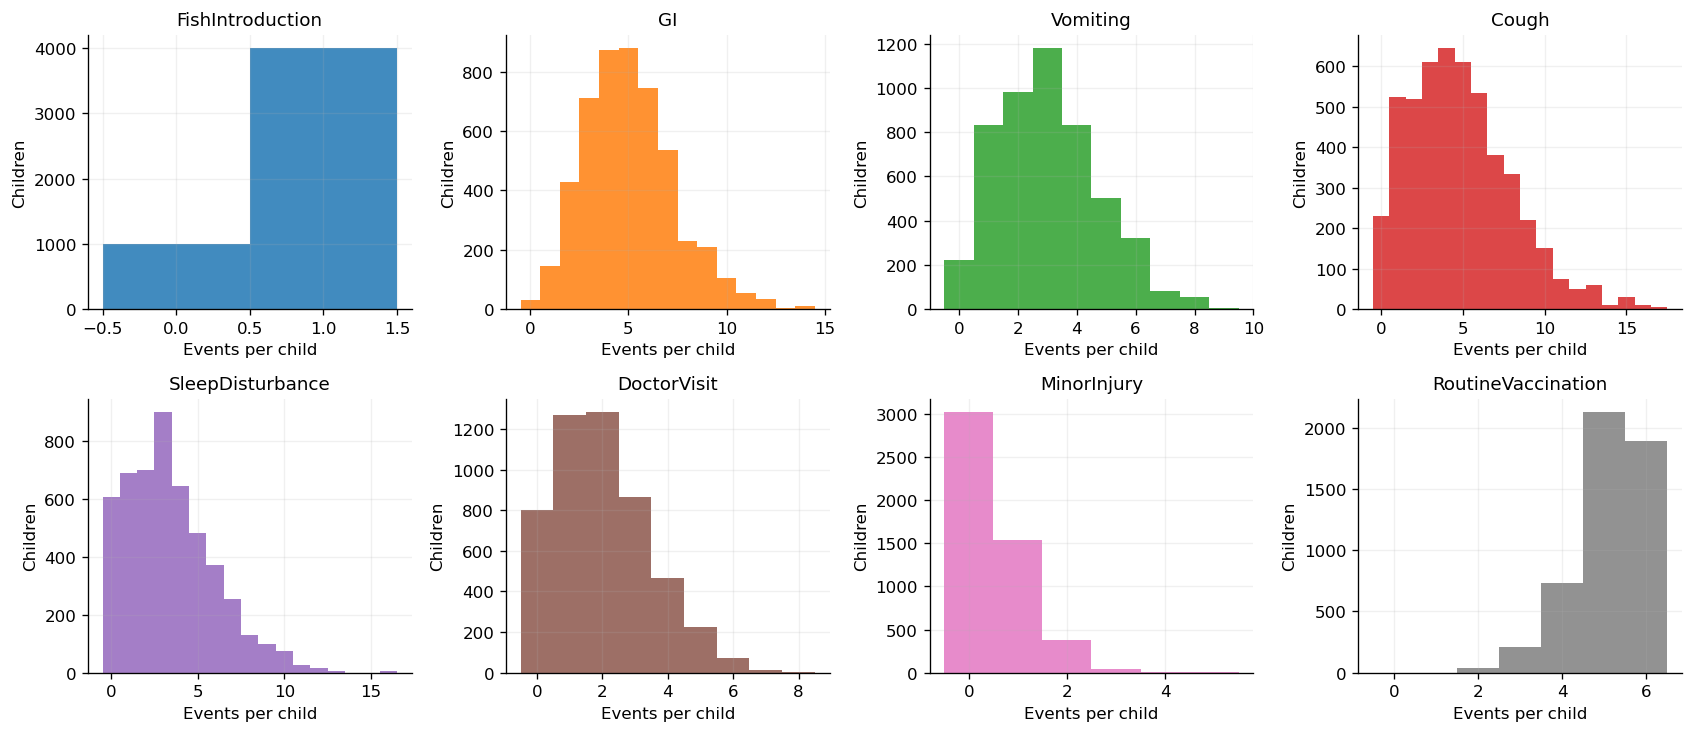

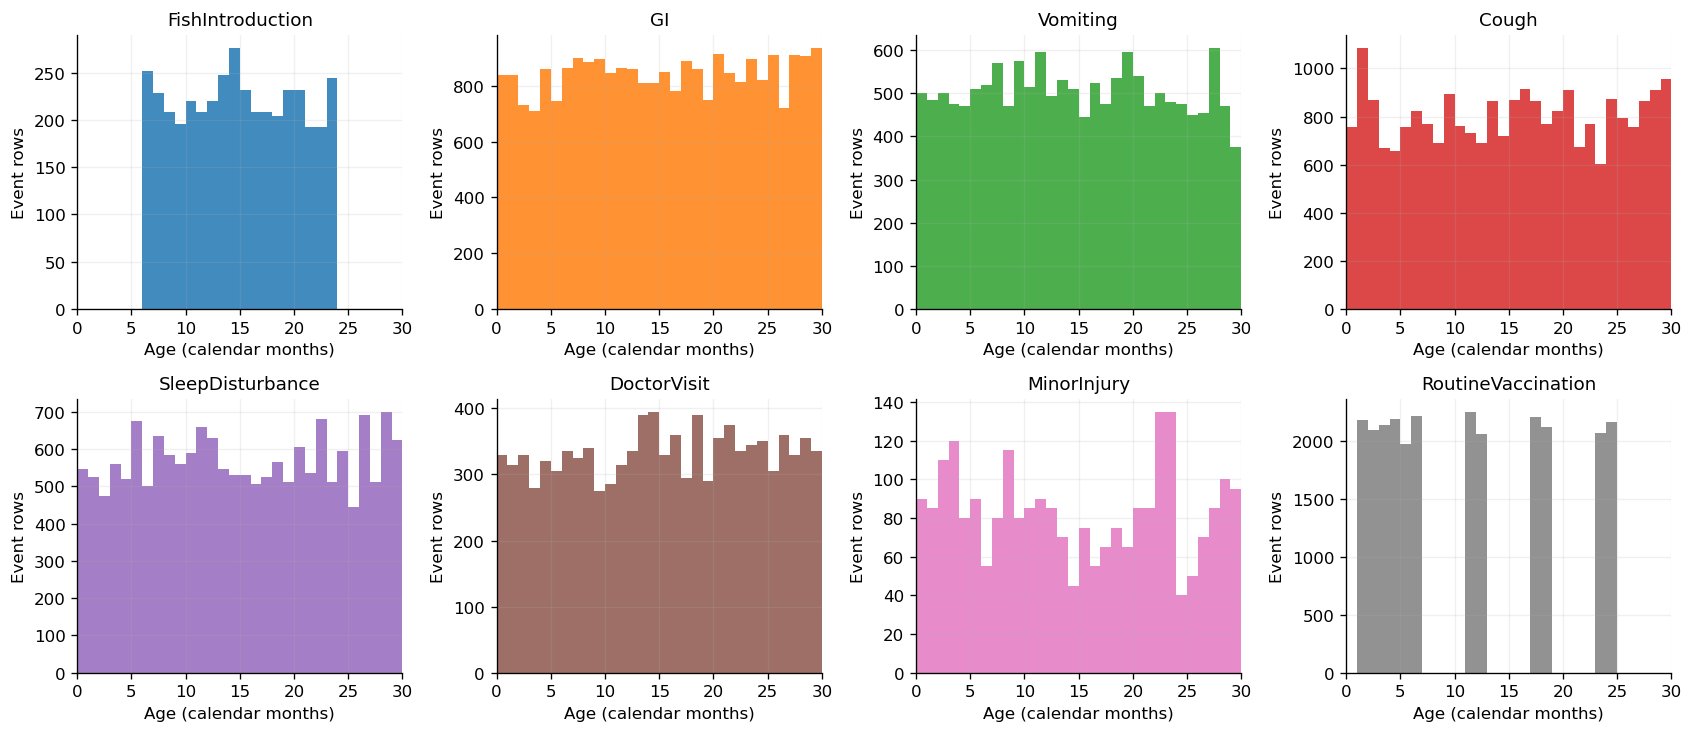

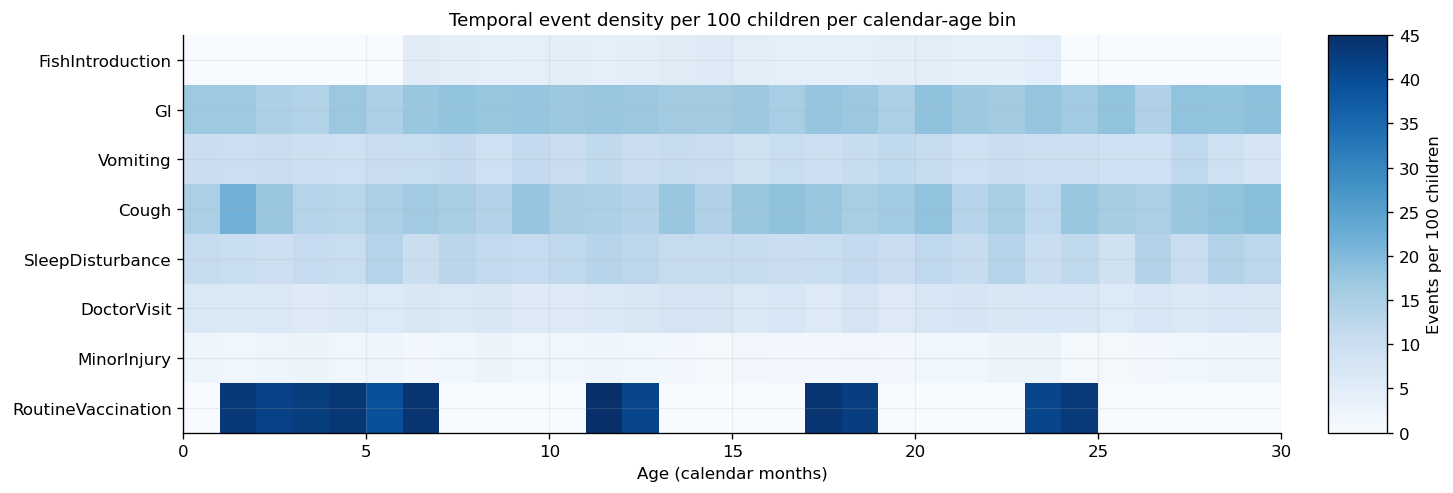

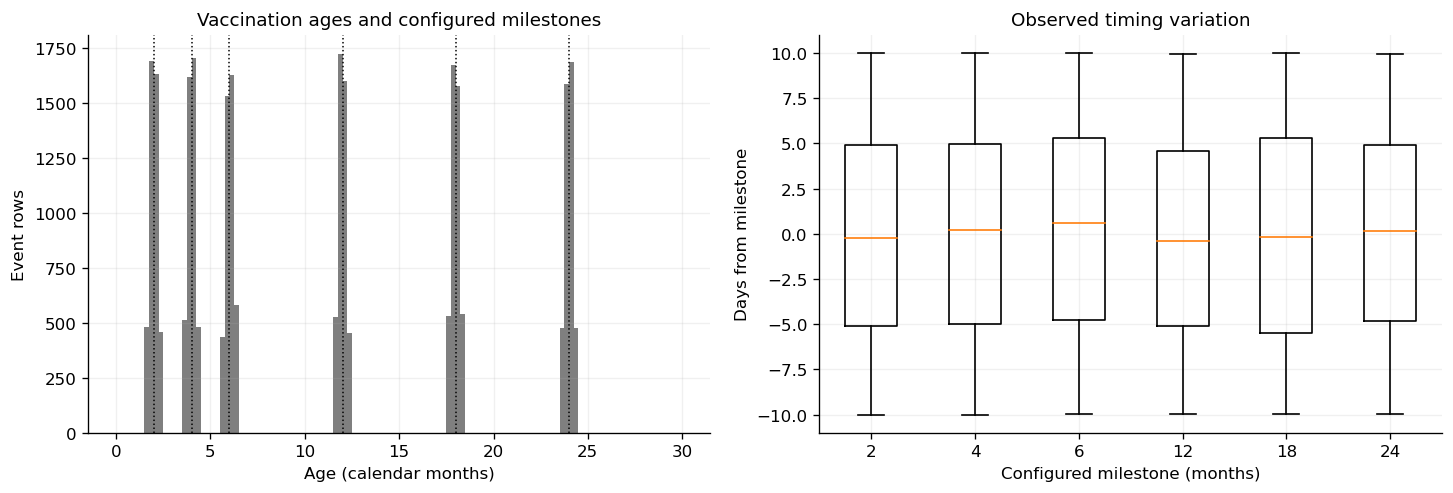

**Interpretation.** Feature means range from 0.499 to 5.126 events per child. Vaccination events are at most 10.00 days from their nearest configured milestone. These mechanisms are synthetic assumptions, not measured clinical rates.

In [2]:
feature_summary = pd.DataFrame({
    'patients_with_event': counts.gt(0).sum(), 'percent_with_event': 100*counts.gt(0).mean(),
    'event_rows': counts.sum(), 'mean_count': counts.mean(), 'median_count': counts.median(),
    'sd_count': counts.std(), 'max_count': counts.max()})
age_summary = events.groupby('feature_name').age_months.agg(['mean','median','std','min','max'])
display(feature_summary.join(age_summary.add_prefix('age_months_')).round(3))
fig, axes = plt.subplots(2,4,figsize=(14,6),constrained_layout=True)
for f, ax in zip(FEATURES,axes.flat):
    values=counts[f]; bins=np.arange(values.max()+2)-.5
    ax.hist(values,bins=bins,color=COLORS[f],alpha=.85)
    ax.set(title=f,xlabel='Events per child',ylabel='Children')
plt.show()
fig, axes = plt.subplots(2,4,figsize=(14,6),constrained_layout=True)
for f, ax in zip(FEATURES,axes.flat):
    ax.hist(events.loc[events.feature_name.eq(f),'age_months'],bins=np.arange(31),
            color=COLORS[f],alpha=.85)
    ax.set(title=f,xlabel='Age (calendar months)',ylabel='Event rows',xlim=(0,30))
plt.show()
monthly = np.array([np.histogram(events.loc[events.feature_name.eq(f),'age_months'],
                                bins=np.arange(31))[0] for f in FEATURES])
fig,ax=plt.subplots(figsize=(12,4),constrained_layout=True)
im=ax.imshow(monthly/len(meta)*100,aspect='auto',extent=(0,30,7.5,-.5),cmap='Blues')
ax.set(yticks=range(8),yticklabels=FEATURES,xlabel='Age (calendar months)',
       title='Temporal event density per 100 children per calendar-age bin')
fig.colorbar(im,ax=ax,label='Events per 100 children');plt.show()
# Milestones are design metadata, not hardcoded descriptive findings.
validation=json.loads((DATA/'validation.json').read_text())
milestones=validation['config']['vaccination_months']
vacc=events.loc[events.feature_name.eq('RoutineVaccination')].copy()
nearest=[]; jitter=[]
for t,b in zip(vacc.time,vacc.birth):
    candidates=[b+pd.DateOffset(months=int(m)) for m in milestones]
    j=int(np.argmin([abs((t-c).total_seconds()) for c in candidates]))
    nearest.append(milestones[j]); jitter.append((t-candidates[j]).total_seconds()/86400)
vacc['milestone']=nearest; vacc['jitter_days']=jitter
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
ax[0].hist(vacc.age_months,bins=np.linspace(0,30,121),color=COLORS['RoutineVaccination'])
for m in milestones: ax[0].axvline(m,color='black',ls=':',lw=.9)
ax[0].set(xlabel='Age (calendar months)',ylabel='Event rows',title='Vaccination ages and configured milestones')
ax[1].boxplot([vacc.loc[vacc.milestone.eq(m),'jitter_days'] for m in milestones],labels=milestones,showfliers=False)
ax[1].set(xlabel='Configured milestone (months)',ylabel='Days from milestone',title='Observed timing variation')
plt.show()
note(f'Feature means range from {counts.mean().min():.3f} to {counts.mean().max():.3f} events per child. '
     f'Vaccination events are at most {vacc.jitter_days.abs().max():.2f} days from their nearest configured milestone. '
     'These mechanisms are synthetic assumptions, not measured clinical rates.')

## 3. Patient timelines

Example selection: lexicographically first patient ID in each stated category; the multiple-symptom example must be distinct from earlier selections. This is a reproducible illustration, not a random or typical-patient sample. Response windows are dataset ground truth, **not learned model anchors or decision paths**.

,example,patient_id,birth,fish_time,R,FA,qualifying_symptoms
0,Documented R=1,N0000_02,2012-06-27,2013-04-12 16:23:07,1,1,1
1,Documented R=0,N0000_01,2012-06-27,2013-04-12 16:23:07,0,0,0
2,Undocumented R=0,N0000_09,2012-06-27,NaT,0,0,0
3,Multiple qualifying symptoms,N0002_05,2012-04-02,2013-08-12 11:11:02,1,1,2


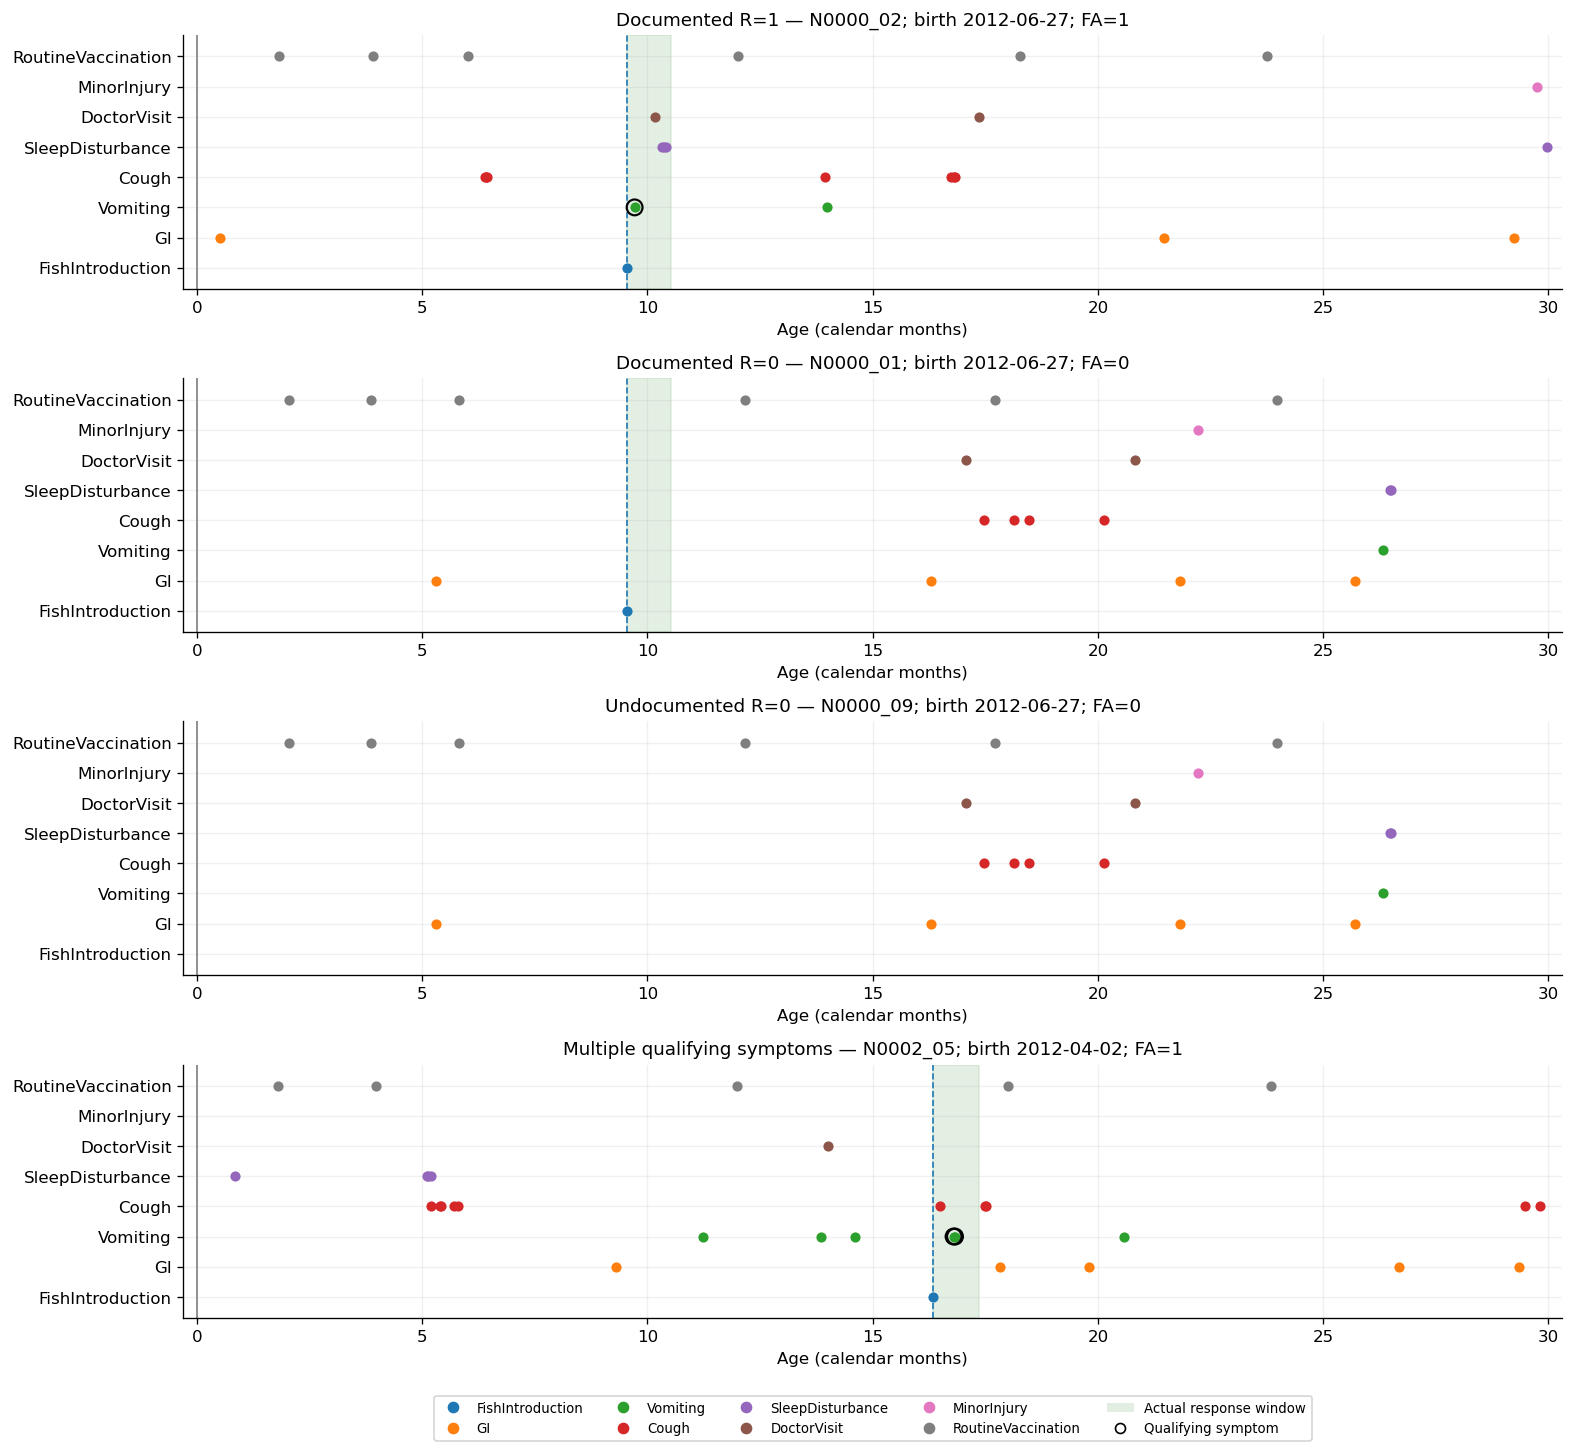

**Interpretation.** Colored dots show observed events; black rings distinguish qualifying GI/Vomiting from other symptom events. A documented R=0 child may have symptoms elsewhere. Undocumented children have no observed fish time and therefore no actual response window.

In [3]:
fish_rows=events.loc[events.feature_name.eq('FishIntroduction')]
fish_times=fish_rows.groupby('patient_id').time.first()
symptoms=events.loc[events.feature_name.isin(['GI','Vomiting'])].copy()
symptoms['fish_time']=symptoms.patient_id.map(fish_times)
symptoms['response_end']=symptoms.fish_time+pd.DateOffset(months=1)
symptoms['qualifies']=symptoms.time.gt(symptoms.fish_time)&symptoms.time.le(symptoms.response_end)
qualifying=symptoms.groupby('patient_id').qualifies.sum().reindex(meta.index,fill_value=0)
meta['qualifying_symptoms']=qualifying.astype(int)
meta['recomputed_R']=qualifying.gt(0).astype(int)
criteria=[('Documented R=1',meta.documented & meta.R.eq(1)),
          ('Documented R=0',meta.documented & meta.R.eq(0)),
          ('Undocumented R=0',~meta.documented & meta.R.eq(0)),
          ('Multiple qualifying symptoms',meta.documented & qualifying.gt(1))]
selected=[]
for label,mask in criteria:
    eligible=sorted(set(meta.index[mask])-set(pid for _,pid in selected))
    if eligible: selected.append((label,eligible[0]))
display(pd.DataFrame([dict(example=label,patient_id=pid,birth=meta.loc[pid,'birth'],
       fish_time=meta.loc[pid,'fish_time'],R=meta.loc[pid,'R'],FA=meta.loc[pid,'FA'],
       qualifying_symptoms=qualifying.loc[pid]) for label,pid in selected]))
fig,axes=plt.subplots(len(selected),1,figsize=(13,3*len(selected)),constrained_layout=True,squeeze=False)
for (label,pid),ax in zip(selected,axes.flat):
    child=meta.loc[pid]; rows=events.loc[events.patient_id.eq(pid)]
    for i,f in enumerate(FEATURES):
        group=rows.loc[rows.feature_name.eq(f)]
        ax.scatter(group.age_months,np.full(len(group),i),color=COLORS[f],s=26,zorder=3)
    if pid in fish_times.index:
        start=fish_times[pid]; end=start+pd.DateOffset(months=1)
        x0=calendar_age(start,child.birth); x1=calendar_age(end,child.birth)
        ax.axvspan(x0,x1,color='#a6cba6',alpha=.3)
        ax.axvline(x0,color=COLORS['FishIntroduction'],ls='--',lw=1)
        hit=symptoms.loc[symptoms.patient_id.eq(pid)&symptoms.qualifies]
        ax.scatter(hit.age_months,[FEATURES.index(f) for f in hit.feature_name],
                   facecolors='none',edgecolors='black',s=90,lw=1.3,zorder=4)
    ax.axvline(0,color='gray',lw=1)
    ax.set(yticks=range(8),yticklabels=FEATURES,xlim=(-.3,30.3),ylim=(-.7,7.7),
           xlabel='Age (calendar months)',title=f'{label} — {pid}; birth {child.birth.date()}; FA={child.FA}')
handles=[Line2D([],[],marker='o',ls='',color=COLORS[f],label=f) for f in FEATURES]
handles += [Patch(facecolor='#a6cba6',alpha=.3,label='Actual response window'),
            Line2D([],[],marker='o',ls='',markerfacecolor='none',color='black',label='Qualifying symptom')]
axes[-1,0].legend(handles=handles,ncol=5,loc='upper center',bbox_to_anchor=(.5,-.28),fontsize=8)
plt.show()
note('Colored dots show observed events; black rings distinguish qualifying GI/Vomiting from other symptom events. '
     'A documented R=0 child may have symptoms elsewhere. Undocumented children have no observed fish time and therefore no actual response window.')

## 4. Temporal ground truth

For a single documented fish event at time $t_f$, **R=1 iff at least one GI or Vomiting event has $t_f < t \leq t_f +$ one calendar month**. Undocumented children have R=0 under this definition. Calendar arithmetic uses `DateOffset(months=1)`; it never substitutes 30 days.

For pooling relative event times, the plot uses elapsed time divided by each child's actual response-window duration. The interval (0,1] then denotes precisely that child's qualifying window; values outside this interval are dimensionless relative times, not calendar months.

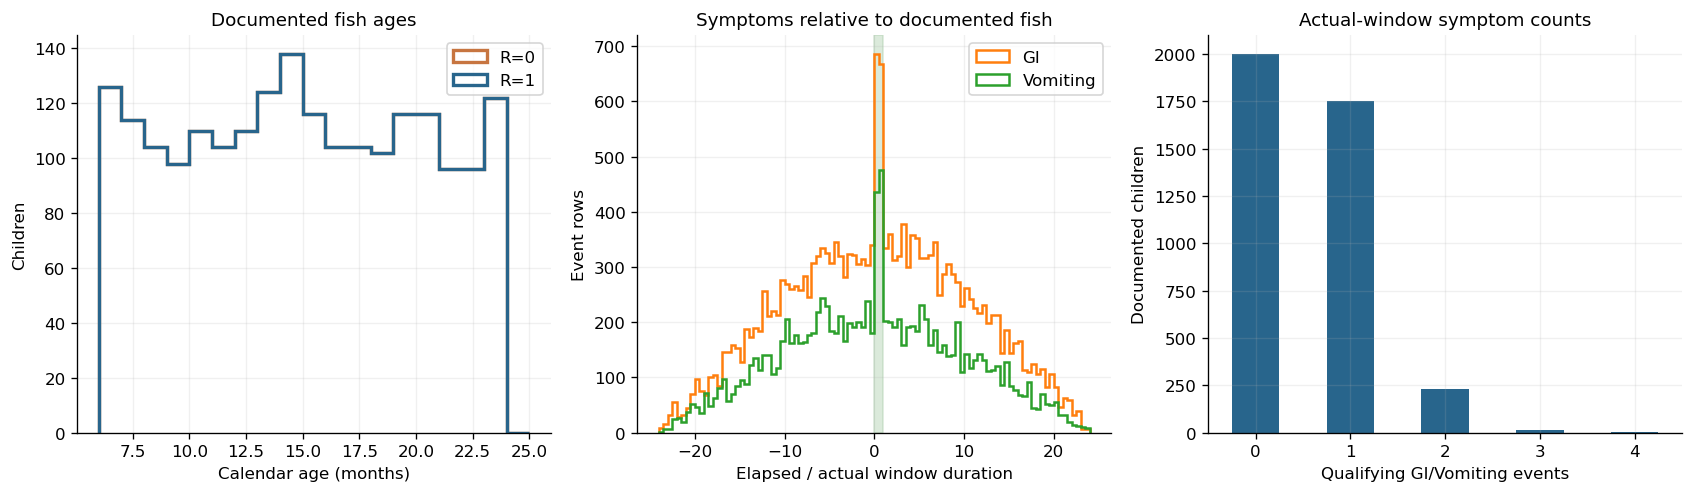

children  FA_cases  FA_prevalence
documented R                                   
False      0      1000        61          0.061
True       0      2000       104          0.052
           1      2000      1818          0.909

**Interpretation.** Recomputing the rule from every observed symptom gives 0 R mismatches. 248 children have multiple qualifying symptoms; 2266 symptom rows qualify. R and FA are intentionally different labels.

In [4]:
doc=meta.loc[meta.documented]
s=symptoms.loc[symptoms.fish_time.notna()].copy()
s['relative_window_units']=(s.time-s.fish_time)/(s.response_end-s.fish_time)
fig,ax=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
for r,color in [(0,'#c77540'),(1,'#28658c')]:
    ax[0].hist(doc.loc[doc.R.eq(r),'fish_age_months'],bins=np.arange(6,26),
               histtype='step',lw=2,label=f'R={r}',color=color)
for f in ['GI','Vomiting']:
    ax[1].hist(s.loc[s.feature_name.eq(f),'relative_window_units'],bins=np.linspace(-24,24,97),
               histtype='step',lw=1.5,label=f,color=COLORS[f])
ax[1].axvspan(0,1,color='#a6cba6',alpha=.4)
ax[0].set(title='Documented fish ages',xlabel='Calendar age (months)',ylabel='Children');ax[0].legend()
ax[1].set(title='Symptoms relative to documented fish',xlabel='Elapsed / actual window duration',ylabel='Event rows');ax[1].legend()
qualifying.loc[doc.index].value_counts().sort_index().plot.bar(ax=ax[2],color='#28658c',rot=0)
ax[2].set(title='Actual-window symptom counts',xlabel='Qualifying GI/Vomiting events',ylabel='Documented children')
plt.show()
display(meta.groupby(['documented','R']).agg(children=('FA','size'),FA_cases=('FA','sum'),FA_prevalence=('FA','mean')))
rule_mismatches=int(meta.R.ne(meta.recomputed_R).sum())
note(f'Recomputing the rule from every observed symptom gives {rule_mismatches} R mismatches. '
     f'{int(qualifying.gt(1).sum())} children have multiple qualifying symptoms; '
     f'{int(qualifying.sum())} symptom rows qualify. R and FA are intentionally different labels.')

## 5. Matching validation

Validate exact within-block distributions using complete event-time signatures, not just similar means. Signature ages are elapsed nanoseconds from birth. Compare documented R groups and the proportional non-fish histories of undocumented children. Full fish-plus-symptom joint matching is neither expected nor desirable: the relative relationship defines R.

,blocks_passing,blocks_checked,blocks_failing
documented_R_balance,500,500,0
one_partition,500,500,0
same_birth,500,500,0
same_followup,500,500,0
FishIntroduction,500,500,0
GI,500,500,0
Vomiting,500,500,0
Cough,500,500,0
SleepDisturbance,500,500,0
DoctorVisit,500,500,0


R,R=0 mean,R=1 mean
FishIntroduction,1.0000,1.0000
GI,5.0520,5.0520
Vomiting,3.0230,3.0230
Cough,4.8190,4.8190
SleepDisturbance,3.4130,3.4130
DoctorVisit,1.9970,1.9970
MinorInjury,0.4990,0.4990
RoutineVaccination,5.1260,5.1260
fish_age_months,14.9206,14.9206
event_count,24.9290,24.9290


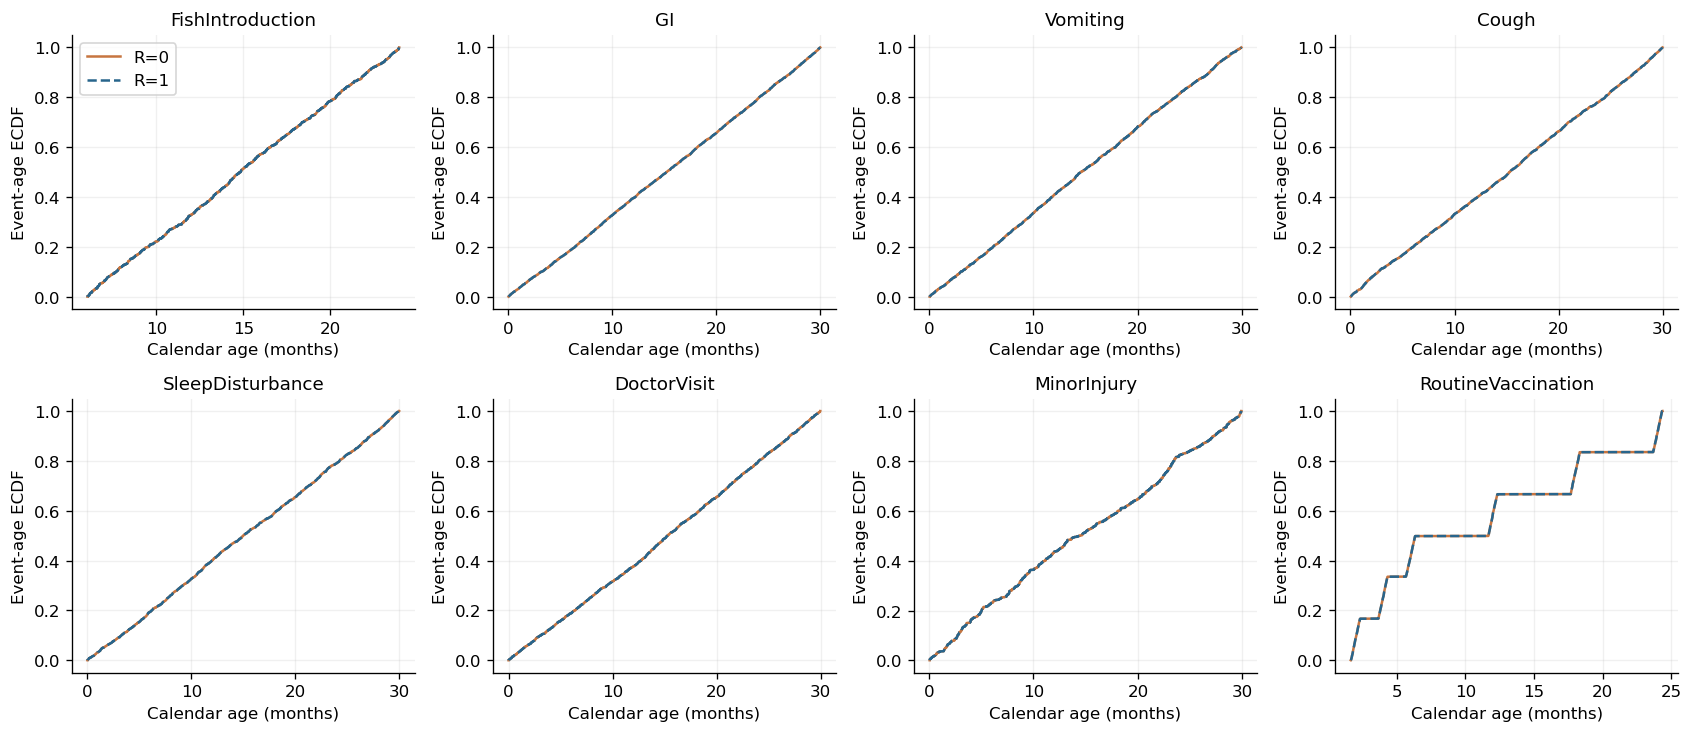

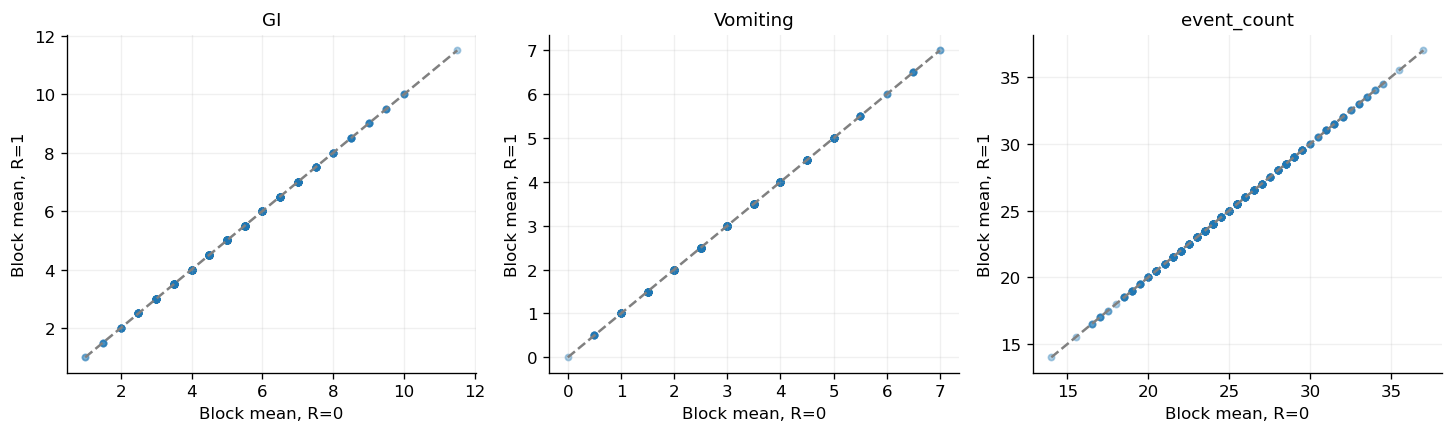

**Interpretation.** Complete marginal histories match in 500/500 blocks; joint non-fish histories match in 500/500. Overlaid ECDFs and diagonal block means reflect verified matching. Joint fish–symptom relationships remain different.

In [5]:
age_ns=(events.time-events.birth).astype('timedelta64[ns]').astype('int64')
events['age_ns']=age_ns
history=events.groupby(['patient_id','feature_name']).age_ns.apply(lambda x: tuple(sorted(x)))
signatures={pid:{f:history.get((pid,f),()) for f in FEATURES} for pid in meta.index}
nonfish=[f for f in FEATURES if f!='FishIntroduction']
def joint(pid,features): return tuple(signatures[pid][f] for f in features)
checks=[]
for block,g in meta.groupby('block'):
    d=g.loc[g.documented]; ids=[d.index[d.R.eq(r)] for r in [0,1]]
    row={'block':block,'documented_R_balance':len(ids[0])==len(ids[1]),
         'one_partition':g.partition.nunique()==1,
         'same_birth':g.birth.nunique()==1,
         'same_followup':g.followup_end.nunique()==1}
    for f in FEATURES:
        row[f]=Counter(signatures[p][f] for p in ids[0])==Counter(signatures[p][f] for p in ids[1])
    c0=Counter(joint(p,nonfish) for p in ids[0]); c1=Counter(joint(p,nonfish) for p in ids[1])
    undoc=Counter(joint(p,nonfish) for p in g.index[~g.documented])
    row['joint_nonfish']=c0==c1
    row['documentation_nonfish']=all(c0[k]*sum(undoc.values())==undoc[k]*sum(c0.values()) for k in set(c0)|set(undoc))
    row['joint_fish_symptoms']=Counter(joint(p,FEATURES[:3]) for p in ids[0])==Counter(joint(p,FEATURES[:3]) for p in ids[1])
    checks.append(row)
matching=pd.DataFrame(checks).set_index('block')
display(pd.DataFrame({'blocks_passing':matching.sum(),'blocks_checked':len(matching),
                      'blocks_failing':(~matching).sum()}))
comparison=counts.loc[doc.index].join(doc[['R','fish_age_months','event_count']])
display(comparison.groupby('R').mean().T.rename(columns={0:'R=0 mean',1:'R=1 mean'}).round(4))
fig,axes=plt.subplots(2,4,figsize=(14,6),constrained_layout=True)
for f,ax in zip(FEATURES,axes.flat):
    for r,color,style in [(0,'#c77540','-'),(1,'#28658c','--')]:
        values=np.sort(events.loc[events.feature_name.eq(f)&events.patient_id.isin(doc.index[doc.R.eq(r)]),'age_months'])
        ax.plot(values,np.arange(1,len(values)+1)/max(1,len(values)),color=color,ls=style,label=f'R={r}')
    ax.set(title=f,xlabel='Calendar age (months)',ylabel='Event-age ECDF')
axes[0,0].legend();plt.show()
block_means=comparison.join(doc.block).groupby(['block','R'])[['GI','Vomiting','event_count']].mean().unstack('R')
fig,axes=plt.subplots(1,3,figsize=(12,3.5),constrained_layout=True)
for f,ax in zip(['GI','Vomiting','event_count'],axes):
    x,y=block_means[(f,0)],block_means[(f,1)]
    ax.scatter(x,y,s=14,alpha=.35); low=min(x.min(),y.min()); high=max(x.max(),y.max())
    ax.plot([low,high],[low,high],ls='--',color='gray')
    ax.set(title=f,xlabel='Block mean, R=0',ylabel='Block mean, R=1')
plt.show()
note(f'Complete marginal histories match in {int(matching[FEATURES].all(axis=1).sum())}/{len(matching)} blocks; '
     f'joint non-fish histories match in {int(matching.joint_nonfish.sum())}/{len(matching)}. '
     'Overlaid ECDFs and diagonal block means reflect verified matching. Joint fish–symptom relationships remain different.')

## 6. Distractor analysis

The earlier panels show distractor frequencies and age distributions. Here, raw count associations are calculated without fitting a model. Rank-based AUC is the probability that a randomly chosen positive-label child has a larger count than a negative-label child, with half credit for ties. It is a descriptive score, not evidence of learned predictive performance. No independence tests or patient-level p-values are used because histories repeat within blocks.

,cohort,feature,label,raw_count_auc,mean_count_label0,mean_count_label1,pearson_correlation
0,All,Cough,R,0.5000,4.8190,4.8190,-0.0000
1,All,Cough,FA,0.5031,4.8134,4.8275,0.0022
2,All,SleepDisturbance,R,0.5000,3.4130,3.4130,0.0000
3,All,SleepDisturbance,FA,0.4991,3.4166,3.4075,-0.0018
4,All,DoctorVisit,R,0.5000,1.9970,1.9970,0.0000
5,All,DoctorVisit,FA,0.5033,1.9894,2.0086,0.0064
6,All,MinorInjury,R,0.5000,0.4990,0.4990,-0.0000
7,All,MinorInjury,FA,0.4975,0.5022,0.4942,-0.0055
8,All,RoutineVaccination,R,0.5000,5.1260,5.1260,-0.0000
9,All,RoutineVaccination,FA,0.4997,5.1276,5.1236,-0.0023


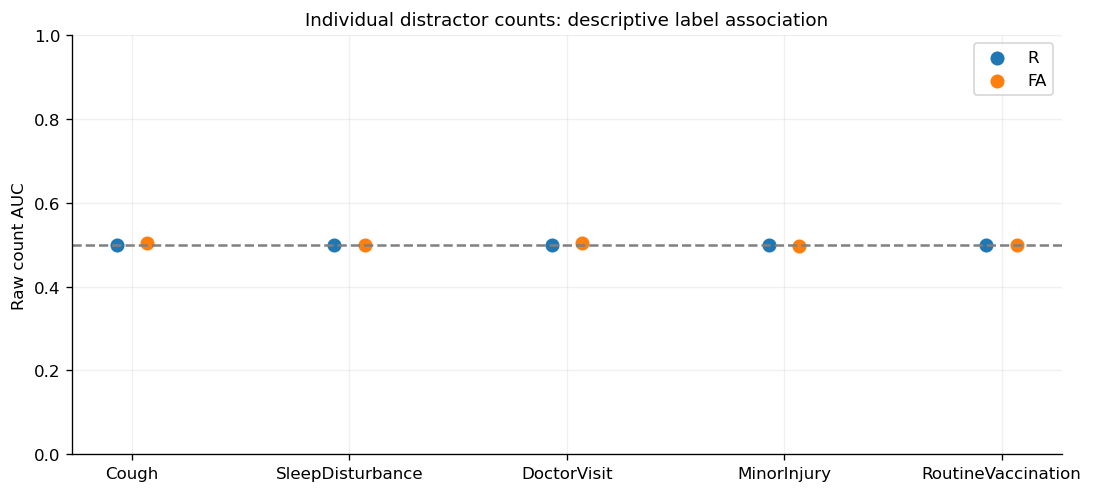

**Interpretation.** All-cohort FA count AUCs range from 0.4975 to 0.5033. These describe individual counts only. Near-chance associations do not prove statistical independence or exclude interactions involving event timing, fish exposure, or other features.

In [6]:
def raw_auc(label,score):
    label=np.asarray(label); score=pd.Series(np.asarray(score))
    n1=int((label==1).sum()); n0=int((label==0).sum())
    if not n1 or not n0: return np.nan
    return (score.rank(method='average')[label==1].sum()-n1*(n1+1)/2)/(n1*n0)

associations=[]
for cohort,subset in [('All',meta),('Documented',doc),('Held-out',meta.loc[meta.partition.eq('test')])]:
    for f in DISTRACTORS:
        for label in ['R','FA']:
            score=counts.loc[subset.index,f]
            associations.append(dict(cohort=cohort,feature=f,label=label,
                raw_count_auc=raw_auc(subset[label],score),
                mean_count_label0=score.loc[subset[label].eq(0)].mean(),
                mean_count_label1=score.loc[subset[label].eq(1)].mean(),
                pearson_correlation=score.corr(subset[label])))
associations=pd.DataFrame(associations)
display(associations.round(4))
fig,ax=plt.subplots(figsize=(9,4),constrained_layout=True)
for j,label in enumerate(['R','FA']):
    rows=associations.loc[associations.cohort.eq('All')&associations.label.eq(label)].set_index('feature').loc[DISTRACTORS]
    ax.scatter(np.arange(len(DISTRACTORS))+(j-.5)*.14,rows.raw_count_auc,label=label,s=55)
ax.axhline(.5,color='gray',ls='--');ax.set(xticks=range(5),xticklabels=DISTRACTORS,
    ylabel='Raw count AUC',ylim=(0,1),title='Individual distractor counts: descriptive label association')
ax.legend();plt.show()
fa_scores=associations.loc[associations.cohort.eq('All')&associations.label.eq('FA'),'raw_count_auc']
note(f'All-cohort FA count AUCs range from {fa_scores.min():.4f} to {fa_scores.max():.4f}. '
     'These describe individual counts only. Near-chance associations do not prove statistical independence '
     'or exclude interactions involving event timing, fish exposure, or other features.')

## 7. Documentation shortcut

Undocumented children have no observed fish event and therefore R=0 by definition. This can make documentation status informative about FA even if non-fish histories are matched. Compare total event density with non-fish density to separate the fish row itself from background observation frequency.

,children,R_prevalence,FA_prevalence,mean_events,mean_nonfish_events,mean_GI,mean_Vomiting
documented,,,,,,,
False,1000,0.0,0.0610,23.929,23.929,5.052,3.023
True,4000,0.5,0.4805,24.929,23.929,5.052,3.023


,patients,documentation_only_FA_auc
cohort,,
All,5000,0.640237
Train,4000,0.637793
Test,1000,0.649989


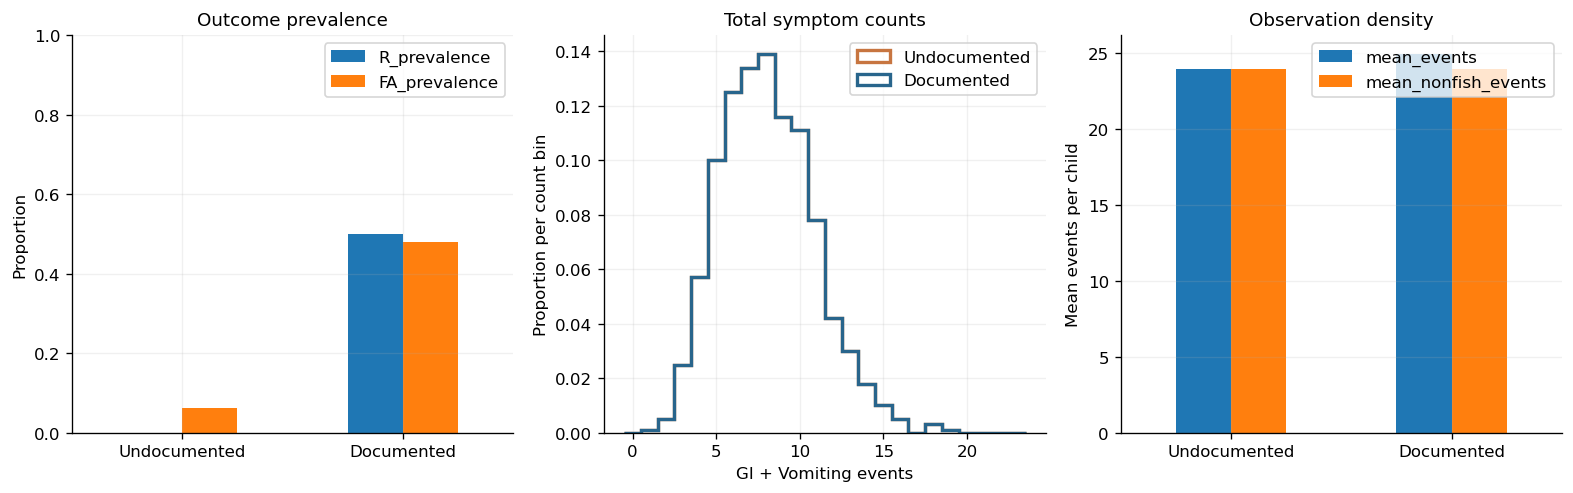

**Interpretation.** Documentation alone has held-out descriptive FA AUC 0.6500. This shortcut is retained by the label mechanism; it should be considered alongside documented-only ON/OFF evaluation. No fitted classifier or saved model predictions are used here.

In [7]:
documentation=meta.groupby('documented').agg(children=('R','size'),R_prevalence=('R','mean'),
    FA_prevalence=('FA','mean'),mean_events=('event_count','mean'),mean_nonfish_events=('nonfish_count','mean'))
for f in ['GI','Vomiting']:
    documentation['mean_'+f]=counts[f].groupby(meta.documented).mean()
display(documentation.round(4))
baselines=[]
for cohort,subset in [('All',meta),('Train',meta.loc[meta.partition.eq('train')]),('Test',meta.loc[meta.partition.eq('test')])]:
    baselines.append({'cohort':cohort,'patients':len(subset),
                      'documentation_only_FA_auc':raw_auc(subset.FA,subset.documented.astype(int))})
baselines=pd.DataFrame(baselines).set_index('cohort');display(baselines)
fig,ax=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
documentation[['R_prevalence','FA_prevalence']].rename(index={False:'Undocumented',True:'Documented'}).plot.bar(ax=ax[0],rot=0)
ax[0].set(title='Outcome prevalence',ylim=(0,1),xlabel='',ylabel='Proportion')
for status,color in [(False,'#c77540'),(True,'#28658c')]:
    ids=meta.index[meta.documented.eq(status)]
    ax[1].hist(counts.loc[ids,['GI','Vomiting']].sum(axis=1),bins=np.arange(25)-.5,density=True,
               histtype='step',lw=2,color=color,label='Documented' if status else 'Undocumented')
documentation[['mean_events','mean_nonfish_events']].rename(index={False:'Undocumented',True:'Documented'}).plot.bar(ax=ax[2],rot=0)
ax[1].set(title='Total symptom counts',xlabel='GI + Vomiting events',ylabel='Proportion per count bin');ax[1].legend()
ax[2].set(title='Observation density',xlabel='',ylabel='Mean events per child');plt.show()
note(f'Documentation alone has held-out descriptive FA AUC {baselines.loc["Test","documentation_only_FA_auc"]:.4f}. '
     'This shortcut is retained by the label mechanism; it should be considered alongside documented-only ON/OFF evaluation. '
     'No fitted classifier or saved model predictions are used here.')

## 8. Data quality and leakage checks

Missing fish timestamps are expected for undocumented children. Exact duplicate observation rows are reported separately rather than automatically rejected. Identical histories shared by different children are part of the matched design. Metadata such as R, FA, block, profile and candidate fish times must never be supplied as observed features.

In [8]:
display(raw.isna().sum().to_frame('Missing observation fields'))
display(patients.isna().sum().to_frame('Missing metadata fields (some expected)'))
fish_counts=counts.FishIntroduction
birth_rows=obs.loc[obs.feature_name.eq(BIRTH)]
birth_counts=birth_rows.groupby('patient_id').size().reindex(meta.index,fill_value=0)
invalid_event_values=int(pd.to_numeric(events.value,errors='coerce').ne(1).sum())
birth_values=pd.to_datetime(birth_rows.value,errors='coerce')
train_blocks=set(meta.loc[meta.partition.eq('train'),'block'])
test_blocks=set(meta.loc[meta.partition.eq('test'),'block'])
duplicates=raw.duplicated(keep=False)
quality=pd.Series({
    'Missing observation cells':int(raw.isna().sum().sum()),
    'Duplicate patient metadata IDs':int(patients.patient_id.duplicated().sum()),
    'Patient-ID symmetric difference':len(set(obs.patient_id)^set(meta.index)),
    'Invalid observation timestamps':int(obs.time.isna().sum()),
    'Invalid birth/follow-up metadata timestamps':int(meta[['birth','followup_end']].isna().sum().sum()),
    'Unexpected feature names':len(set(obs.feature_name)-set(FEATURES+[BIRTH])),
    'Missing required feature types':len(set(FEATURES+[BIRTH])-set(obs.feature_name)),
    'Event values other than 1 or invalid':invalid_event_values,
    'Invalid birth-anchor values':int(birth_values.isna().sum()),
    'Birth-anchor value mismatches':int(birth_values.ne(birth_rows.patient_id.map(meta.birth)).sum()),
    'Birth-anchor time mismatches':int(birth_rows.time.ne(birth_rows.patient_id.map(meta.birth)).sum()),
    'Patients with birth-anchor count != 1':int(birth_counts.ne(1).sum()),
    'Rows outside observed follow-up':int((obs.time.lt(obs.patient_id.map(meta.birth))|obs.time.gt(obs.patient_id.map(meta.followup_end))).sum()),
    'Follow-up not 30 calendar months':int(meta.followup_end.ne(meta.birth+pd.DateOffset(months=30)).sum()),
    'Documented patients without exactly one fish event':int(fish_counts.loc[meta.documented].ne(1).sum()),
    'Undocumented patients with fish events':int(fish_counts.loc[~meta.documented].ne(0).sum()),
    'Documented patients missing metadata fish time':int(meta.loc[meta.documented,'fish_time'].isna().sum()),
    'Undocumented patients with metadata fish time':int(meta.loc[~meta.documented,'fish_time'].notna().sum()),
    'Observed fish vs metadata timestamp mismatches':int(fish_times.ne(meta.fish_time.reindex(fish_times.index)).sum()),
    'R mismatches with all observed symptoms':rule_mismatches,
    'Documented R=0 with qualifying symptom':int((meta.documented&meta.R.eq(0)&qualifying.gt(0)).sum()),
    'Matched blocks spanning train/test':len(train_blocks&test_blocks),
    'Unknown partition values':int((~meta.partition.isin(['train','test'])).sum()),
    'Invalid R or FA values':int((~meta.R.isin([0,1])).sum()+(~meta.FA.isin([0,1])).sum()),
    'FA sampling-probability metadata mismatches':int(meta.fa_probability.ne(np.where(meta.R.eq(1),.9,.05)).sum()),
    'Unexpected observation columns':len(set(raw.columns)-{'patient_id','time','feature_name','value'}),
})
display(quality.to_frame('Count (zero expected)'))
duplicate_summary=pd.Series({'Rows participating in exact duplicates':int(duplicates.sum()),
                             'Extra exact duplicate rows':int(raw.duplicated().sum()),
                             'Unique complete non-fish histories':len(set(joint(pid,nonfish) for pid in meta.index))})
display(duplicate_summary.to_frame('Count (descriptive, not automatic errors)'))
# Detect identical non-fish histories crossing partitions, beyond block IDs.
history_partitions={}
for pid,row in meta.iterrows():
    history_partitions.setdefault(joint(pid,nonfish),set()).add(row.partition)
history_overlap=sum(len(parts)>1 for parts in history_partitions.values())
display(pd.Series({'Identical complete non-fish histories across partitions':history_overlap}).to_frame('Count'))
print('Observation columns:',list(raw.columns))
issues=quality.loc[quality.ne(0)]
note(f'{len(issues)} zero-expected quality checks are nonzero; '
     f'{int(raw.duplicated().sum())} extra exact duplicate rows are reported separately. '
     f'{history_overlap} complete non-fish history signatures occur in both partitions. '
     'These checks cover explicit metadata leakage and matched-history overlap, not every possible statistical shortcut.')

,Missing observation fields
patient_id,0
time,0
feature_name,0
value,0


,Missing metadata fields (some expected)
patient_id,0
block,0
profile,0
history_id,0
partition,0
documented,0
birth,0
followup_end,0
a,0
b,0


,Count (zero expected)
Missing observation cells,0
Duplicate patient metadata IDs,0
Patient-ID symmetric difference,0
Invalid observation timestamps,0
Invalid birth/follow-up metadata timestamps,0
Unexpected feature names,0
Missing required feature types,0
Event values other than 1 or invalid,0
Invalid birth-anchor values,0
Birth-anchor value mismatches,0


,"Count (descriptive, not automatic errors)"
Rows participating in exact duplicates,0
Extra exact duplicate rows,0
Unique complete non-fish histories,1000


,Count
Identical complete non-fish histories across partitions,0


Observation columns: ['patient_id', 'time', 'feature_name', 'value']


**Interpretation.** 0 zero-expected quality checks are nonzero; 0 extra exact duplicate rows are reported separately. 0 complete non-fish history signatures occur in both partitions. These checks cover explicit metadata leakage and matched-history overlap, not every possible statistical shortcut.

## 9. Final summary

The summary below is computed from the analysis, not copied from a saved report. No conclusions about learned anchors or ON/OFF model performance follow from EDA alone.

In [9]:
summary_rows=[
    ('Cohort',f'{len(meta):,} patients; {len(events):,} events; {meta.block.nunique()} matched blocks'),
    ('Ground truth',f'{rule_mismatches} R mismatches; {int(qualifying.gt(0).sum())} positive response windows'),
    ('Marginal matching',f'{int(matching[FEATURES].all(axis=1).sum())}/{len(matching)} blocks match all complete per-feature histories'),
    ('Joint non-fish matching',f'{int(matching.joint_nonfish.sum())}/{len(matching)} blocks pass'),
    ('Documentation matching',f'{int(matching.documentation_nonfish.sum())}/{len(matching)} blocks have proportional identical non-fish histories'),
    ('Joint fish/symptom matching',f'{int(matching.joint_fish_symptoms.sum())}/{len(matching)} blocks match; joint differences carry the intended rule'),
    ('Saved split',f'{len(train_blocks&test_blocks)} overlapping blocks; {history_overlap} overlapping non-fish history signatures'),
    ('Documentation shortcut',f'Test documentation-only FA AUC = {baselines.loc["Test","documentation_only_FA_auc"]:.4f}'),
    ('Quality',f'{len(issues)} nonzero zero-expected checks; inspect the table above'),
]
display(pd.DataFrame(summary_rows,columns=['Property','Observed result']))
note('This is a selected, matched synthetic benchmark, not a population sample. '
     'Matching verifies strong marginal balance but preserves joint fish–symptom timing information; '
     'birth-relative combinations may still capture some of it. Repeated histories reduce the number of independent units, '
     'so future uncertainty estimates should respect blocks. Distractor rates and milestones are design assumptions. '
     'Documentation predicts FA under the retained probabilistic label mechanism. '
     'The truth rule requires a strict lower boundary; this dataset cannot establish model behavior at unobserved exact-boundary cases.')
# Verify this EDA left every original dataset artifact unchanged.
after_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in DATA.iterdir() if p.is_file()}
assert source_hashes==after_hashes, 'Dataset artifacts changed during execution'
print('All original dataset file hashes unchanged. EDA complete; no models used.')

,Property,Observed result
0,Cohort,"5,000 patients; 123,645 events; 500 matched bl..."
1,Ground truth,0 R mismatches; 2000 positive response windows
2,Marginal matching,500/500 blocks match all complete per-feature ...
3,Joint non-fish matching,500/500 blocks pass
4,Documentation matching,500/500 blocks have proportional identical non...
5,Joint fish/symptom matching,0/500 blocks match; joint differences carry th...
6,Saved split,0 overlapping blocks; 0 overlapping non-fish h...
7,Documentation shortcut,Test documentation-only FA AUC = 0.6500
8,Quality,0 nonzero zero-expected checks; inspect the ta...


**Interpretation.** This is a selected, matched synthetic benchmark, not a population sample. Matching verifies strong marginal balance but preserves joint fish–symptom timing information; birth-relative combinations may still capture some of it. Repeated histories reduce the number of independent units, so future uncertainty estimates should respect blocks. Distractor rates and milestones are design assumptions. Documentation predicts FA under the retained probabilistic label mechanism. The truth rule requires a strict lower boundary; this dataset cannot establish model behavior at unobserved exact-boundary cases.

All original dataset file hashes unchanged. EDA complete; no models used.
